<center><font size=6>PredictivePulse – Smart Machine Failure Prediction</center></font>


<center><p float="center">
  <img src="https://images.openai.com/static-rsc-4/ch86LBjT5wmXMhoUeJ0vHi-GWCHsSo6uuJlIWh0-vAI7V27kHECot-WJTTBleGt3NroX9qNEUGkCcfE_abSPfzZ2xH4pH47NmSAs3E8Lm7zrCea6Ge3SoFIpzwRsW-7Y7G6AC_U6jdVxzI--InIx640dTcjLcPQyQW_VDbODkqSS1bOntzTO3e-GP3vkjIdB?purpose=fullsize"width=720></a>

# **Problem Statement**

## Objective

<font size=4> **PredictivePulse** is a machine learning project that predicts whether an industrial machine is likely to fail based on sensor readings and operating conditions. The goal is to identify possible failures early so companies can perform maintenance before a machine breaks down.

## Business Context

<font size=4> Manufacture companies significally face challenge to  manually analyse the machine is like to fail or not is inefficient and consuming - Time. This **Predictive Pulse** project automatically predicts whether an industrial machine is likely to fail or not.

## Data Description

- Records: 650 machine-operation records.
- Features: Air temperature, process temperature, rotational speed, torque, and tool wear.
- Target Variable: Machine failure (0 = No failure, 1 = Failure).
- Purpose: Predict machine failures using sensor and operational data.

# **Import Necessary Libraries**

In [1]:
# Pandas: Used for data manipulation and analysis.
import pandas as pd

# NumPy: Used for numerical operations and array handling.
import numpy as np

# Matplotlib: Used for creating static, interactive, and animated visualizations.
import matplotlib.pyplot as plt

# Seaborn: Built on top of Matplotlib, provides a high-level interface for statistical graphics.
import seaborn as sns

# Scikit-learn (sklearn): A comprehensive library for machine learning tasks, including model tuning, performance evaluation, and data preprocessing.
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    recall_score
)
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Classification Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# **Load the Dataset**

* We load our dataset from Google Drive.
* The file named **`ai4i2020.csv`** has been stored there.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

# Load the dataset
data = pd.read_csv('/content/drive/My Drive/Project_Dataset/ai4i2020.csv')

Mounted at /content/drive


# **Data Overview**

In [3]:
data.shape

(650, 14)

- The dataset consists of 650 rows and 14 columns

**First 10 rows of the DataFrame.**

In [4]:
data.head(10)

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,4442,L51621,L,302.5,310.2,1329,50.6,148,1,0,1,0,0,0
1,7735,L54914,L,300.6,312.0,1670,29.4,134,0,0,0,0,0,0
2,1163,L48342,L,296.9,307.8,1400,57.1,202,1,0,0,0,1,0
3,4122,M18981,M,302.1,310.7,1364,47.8,213,1,0,1,0,0,0
4,8232,L55411,L,299.1,310.5,1419,48.8,76,0,0,0,0,0,0
5,4072,L51251,L,301.9,310.6,1331,68.6,85,1,0,0,1,0,0
6,9305,L56484,L,298.3,309.1,1537,43.0,123,0,0,0,0,0,0
7,8380,L55559,L,298.8,309.9,1629,31.9,49,0,0,0,0,0,0
8,4654,M19513,M,303.1,311.1,1594,35.5,13,0,0,0,0,0,0
9,8395,M23254,M,298.6,309.5,1566,38.1,89,0,0,0,0,0,0


**Last 10 rows of the DataFrame.**

In [5]:
data.tail(10)

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
640,6086,L53265,L,300.9,310.6,1538,36.7,3,0,0,0,0,0,0
641,2750,M17609,M,299.7,309.2,1685,28.9,179,1,0,0,0,0,0
642,8000,M22859,M,300.9,312.1,1617,31.0,148,0,0,0,0,0,0
643,1809,L48988,L,298.1,307.7,2567,12.8,125,1,0,0,1,0,0
644,7391,M22250,M,299.7,310.5,1490,41.2,126,0,0,0,0,0,0
645,8413,M23272,M,298.6,309.7,1314,49.7,136,0,0,0,0,0,0
646,7393,M22252,M,299.7,310.5,1492,39.3,131,0,0,0,0,0,0
647,3157,L50336,L,300.4,309.7,1467,36.9,131,0,0,0,0,0,0
648,2332,L49511,L,299.3,308.6,1384,53.6,218,1,0,0,0,1,0
649,8090,L55269,L,300.1,311.3,1676,30.3,151,0,0,0,0,0,0


**Count of Machine Failure**

In [6]:
sum(data.loc[data['Machine failure'] == 1, 'Machine failure'])

325

**Summary of categorical variables.**

In [7]:
 data.describe(include='object')

,Product ID,Type
count,650,650
unique,650,3
top,L55269,L
freq,1,420


**The names, data types, and number of entries in the columns of the dataset.**

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 650 entries, 0 to 649
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      650 non-null    int64  
 1   Product ID               650 non-null    object 
 2   Type                     650 non-null    object 
 3   Air temperature [K]      650 non-null    float64
 4   Process temperature [K]  650 non-null    float64
 5   Rotational speed [rpm]   650 non-null    int64  
 6   Torque [Nm]              650 non-null    float64
 7   Tool wear [min]          650 non-null    int64  
 8   Machine failure          650 non-null    int64  
 9   TWF                      650 non-null    int64  
 10  HDF                      650 non-null    int64  
 11  PWF                      650 non-null    int64  
 12  OSF                      650 non-null    int64  
 13  RNF                      650 non-null    int64  
dtypes: float64(3), int64(9), o

**Statistical summary of the dataset**

In [9]:
data.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,650.000000,650.000000,650.000000,650.000000,650.000000,650.000000,650.000000,650.000000,650.000000,650.000000,650.000000,650.000000
mean,4880.186154,300.405385,310.137846,1514.121538,45.072769,126.350769,0.500000,0.069231,0.167692,0.138462,0.144615,0.001538
std,2670.642141,2.008914,1.381893,293.060950,14.038498,70.634261,0.500385,0.254042,0.373881,0.345650,0.351983,0.039223
min,1.000000,295.600000,306.100000,1181.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2837.750000,298.700000,309.100000,1359.000000,36.925000,64.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,4612.500000,300.500000,310.200000,1430.500000,46.150000,130.000000,0.500000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,7087.000000,302.200000,311.100000,1549.750000,54.500000,193.750000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,10000.000000,304.400000,313.700000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


**Check Dulpicate rows**

In [10]:
print("Dulpicates: ", data.duplicated().sum())

Dulpicates:  0


**Check Missing values**

In [11]:
data.isnull().sum()

,0
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


# **Exploratory Data Analysis**

**Now Let's understand the structure of our dataset.**

- In this section, we analyze the dataset to uncover underlying patterns, identify anomalies, and understand relationships between operating features and machine failures.

- EDA helps us better understand the data and prepares us for building a more accurate and meaningful model.

 ## **Univariate Analysis**

**Visualized machine failure distribution using count plots.**

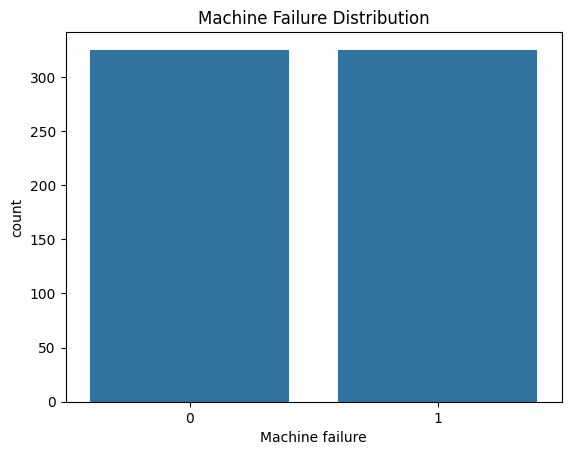

In [12]:
# Machine failure distribution
sns.countplot(data=data, x="Machine failure")
plt.title("Machine Failure Distribution")
plt.show()

**Visualized Sensor distribution using histograms.**

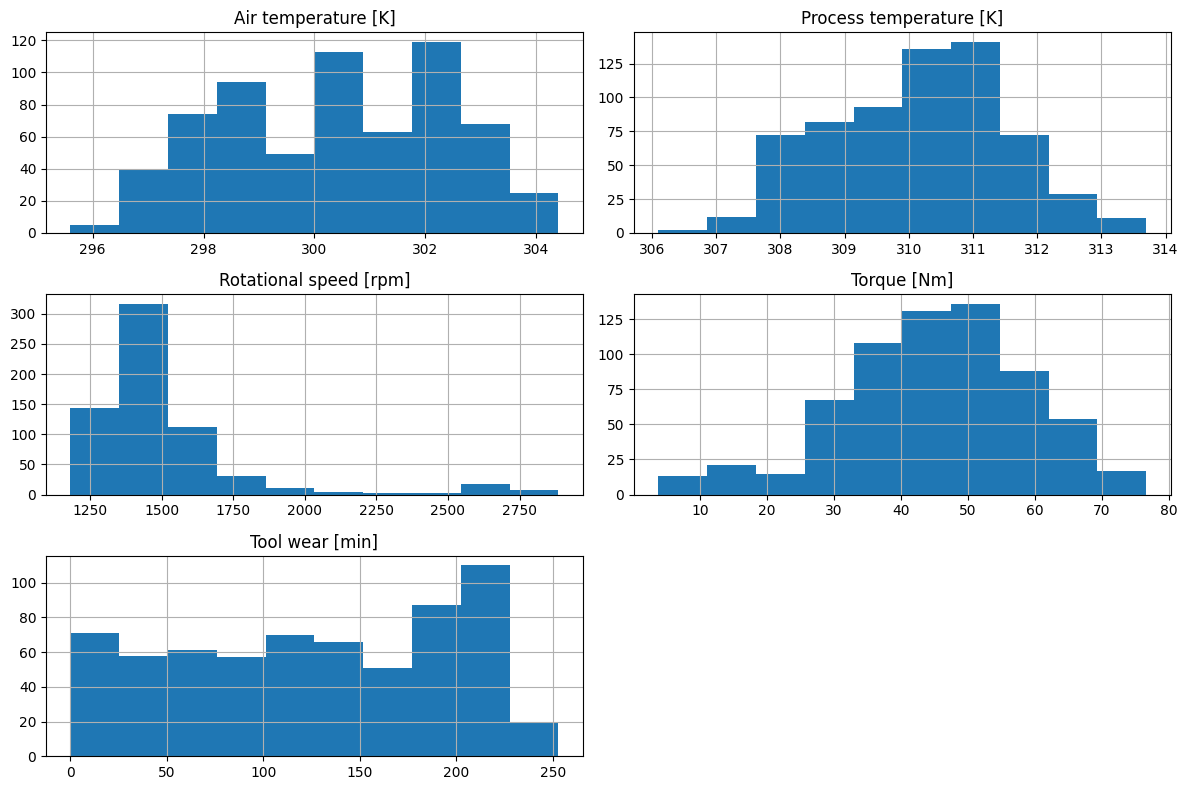

In [13]:
# Sensor distributions
data[[
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]].hist(figsize=(12, 8))
plt.tight_layout()
plt.show()

## **Bivariate Analysis**

**Examined sensor features and outliers using statistical summaries and boxplots.**

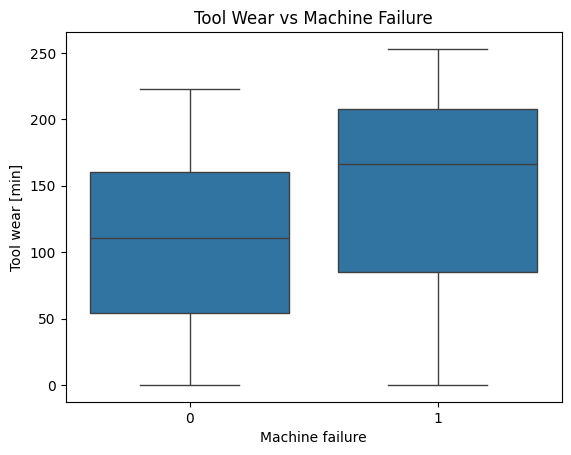

In [14]:
# Failure vs tool wear
sns.boxplot(data=data, x="Machine failure", y="Tool wear [min]")
plt.title("Tool Wear vs Machine Failure")
plt.show()

**Used correlation heatmaps to explore relationships between machine operating conditions and failures.**

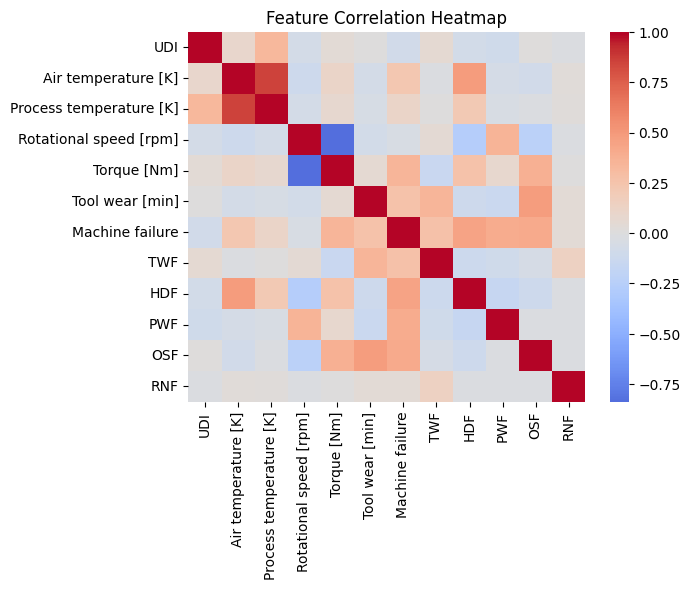

In [15]:
# Correlation heatmap
numeric_df = data.select_dtypes(include="number")

sns.heatmap(numeric_df.corr(), cmap="coolwarm", center=0)
plt.title("Feature Correlation Heatmap")
plt.show()

# **Data Preprocessing**

- **Data preprocessing** prepares the dataset in a clean and numerical format before model training.

- **Encode categorical variables** by converting text values into numerical values.

- **Split the dataset** into training and testing sets (typically 80% training and 20% testing).

- The **training set** is used to train the machine learning model.

- The **testing set** is used to evaluate the model's performance on unseen data.

- These preprocessing steps help improve model accuracy and generalization.

**Let's Remove the Irrelevant column.**

- Droping `UDI`, `Product ID`, and the Failure-mode columns (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`). The IDs aren't useful predictive features, and the Failure-mode labels can leak information about the target. It's doesn't contribute to model building.


In [16]:
# 3. Remove IDs and failure-mode labels
leakage_cols = ["UDI", "Product ID", "TWF", "HDF", "PWF", "OSF", "RNF"]

data = data.drop(leakage_cols, axis = 1)

**Encode the column `Type` by using One-Hot Encoding.**

In [17]:
# 4. Encode categorical features
data = pd.get_dummies(data, columns=["Type"], drop_first=True, dtype=int)

## **Split the data**

- **Store the target Variable.**
- **The data split into 80% for training and 20% testing.**

In [18]:
# 2. Select target
X = data.drop("Machine failure", axis=1)
y = data["Machine failure"]

# 5. Split the data into training and testing, stratifying by the target variable
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# Print the shapes of the resulting sets to verify the split
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (520, 7)
X_test shape: (130, 7)
y_train shape: (520,)
y_test shape: (130,)


# **Model Building**

**A blank dataframe for model_evaluation**

In [19]:
model_evaluation = pd.DataFrame(columns=['Model', 'Train_Accuracy', 'Train_Precision', 'Train_Recall', 'Train_F1',
                                           'Test_Accuracy', 'Test_Precision', 'Test_Recall', 'Test_F1'])

## **Model 1 — Logistic Regression**

In [20]:
# Initialize Logistic Regression
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train model
lr_model.fit(X_train, y_train)

# Predict on Testing data
lr_pred_test = lr_model.predict(X_test)

# predict on Training Data
lr_pred_train = lr_model.predict(X_train)

# Store the results in model_evaluation
model_evaluation.loc[len(model_evaluation)] = ["Logistic Regression", accuracy_score(y_train, lr_pred_train), precision_score(y_train, lr_pred_train, zero_division=0),
                                               recall_score(y_train, lr_pred_train, zero_division=0), f1_score(y_train, lr_pred_train, zero_division=0),
                                               accuracy_score(y_test, lr_pred_test), precision_score(y_test, lr_pred_test, zero_division=0),
                                               recall_score(y_test, lr_pred_test, zero_division=0), f1_score(y_test, lr_pred_test, zero_division=0)]

# Show the model evaluation results dataframe
print("\nModel Evaluation Results:")
model_evaluation


Model Evaluation Results:


,Model,Train_Accuracy,Train_Precision,Train_Recall,Train_F1,Test_Accuracy,Test_Precision,Test_Recall,Test_F1
0,Logistic Regression,0.828846,0.832685,0.823077,0.827853,0.769231,0.769231,0.769231,0.769231


* **Diagnostic Conclusion:** **Underfitting.** It generalizes similarly across splits but underperforms overall (Train F1: ~82.79%, Test F1: ~76.92%, Test Recall: ~76.92%). Being a linear model, it is too simple to capture complex, non-linear sensor relationships.

## **Model 2 — Random Forest**

In [21]:
 # Initialize Logistic Regression
 rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

 # Train Model
 rf_model.fit(X_train, y_train)

 # Predict on Testing Data
 rf_pred_test = rf_model.predict(X_test)

 # predict on Training data
 rf_pred_train = rf_model.predict(X_train)

 # Store the results in model_evaluation
model_evaluation.loc[len(model_evaluation)] = ["Random Forest", accuracy_score(y_train, rf_pred_train), precision_score(y_train, rf_pred_train, zero_division=0),
                                               recall_score(y_train, rf_pred_train, zero_division=0), f1_score(y_train, rf_pred_train, zero_division=0),
                                               accuracy_score(y_test, rf_pred_test), precision_score(y_test, rf_pred_test, zero_division=0),
                                               recall_score(y_test, rf_pred_test, zero_division=0), f1_score(y_test, rf_pred_test, zero_division=0)]


# Show the model evaluation results dataframe
print("\nModel Evaluation Results:")
model_evaluation



Model Evaluation Results:


,Model,Train_Accuracy,Train_Precision,Train_Recall,Train_F1,Test_Accuracy,Test_Precision,Test_Recall,Test_F1
0,Logistic Regression,0.828846,0.832685,0.823077,0.827853,0.769231,0.769231,0.769231,0.769231
1,Random Forest,1.000000,1.000000,1.000000,1.000000,0.892308,0.892308,0.892308,0.892308


* **Diagnostic Conclusion:** **Overfitting.** It perfectly memorized the training set (Train F1: 100.00%), but its performance falls on unseen testing data (Test F1: ~89.23%, Test Recall: ~89.23%), signaling high variance.

## **Model 3 — Gradient Boosting**

In [22]:
gb_model = GradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    random_state=42
)

# Train Model
gb_model.fit(X_train, y_train)

# Predict on Testing Data
gb_pred_test = gb_model.predict(X_test)

# predict on Training data
gb_pred_train = gb_model.predict(X_train)

# Store the results in model_evaluation
model_evaluation.loc[len(model_evaluation)] = ["Gradient Boosting", accuracy_score(y_train, gb_pred_train), precision_score(y_train, gb_pred_train, zero_division=0),
                                               recall_score(y_train, gb_pred_train, zero_division=0), f1_score(y_train, gb_pred_train, zero_division=0),
                                               accuracy_score(y_test, gb_pred_test), precision_score(y_test, gb_pred_test, zero_division=0),
                                               recall_score(y_test, gb_pred_test, zero_division=0), f1_score(y_test, gb_pred_test, zero_division=0)]

# Show the model evaluation results dataframe
print("\nModel Evaluation Results:")
model_evaluation


Model Evaluation Results:


,Model,Train_Accuracy,Train_Precision,Train_Recall,Train_F1,Test_Accuracy,Test_Precision,Test_Recall,Test_F1
0,Logistic Regression,0.828846,0.832685,0.823077,0.827853,0.769231,0.769231,0.769231,0.769231
1,Random Forest,1.000000,1.000000,1.000000,1.000000,0.892308,0.892308,0.892308,0.892308
2,Gradient Boosting,0.978846,0.977011,0.980769,0.978887,0.900000,0.893939,0.907692,0.900763


* **Diagnostic Conclusion:** **Best Balanced Model (With Hyperparameter Tuning).** By introducing a subsample rate of 0.8 and a learning rate of 0.05, it strikes a highly optimized balance (Train F1: ~97.89%, Test F1: ~90.08%, Test Recall: ~90.77%), outperforming both the basic models and reducing overfitting

## **Overall Model Evaluation Summary**

| Model | Train F1-Score | Test F1-Score | Test Recall | Diagnostic Conclusion |
| :--- | :---: | :---: | :---: | :--- |
| **Logistic Regression** | 82.79% | 76.92% | 76.92% | **Underfitting:** Highly stable but lacks the model complexity to capture non-linear relationships, resulting in lower recall. |
| **Random Forest** | 100.00% | 89.23% | 89.23% | **Overfitting:** Perfectly memorized the training data, leading to a performance drop on unseen test data. |
| **Gradient Boosting (Tuned)** | 97.89% | 90.08% | 90.77% | **Best Model:** Optimal trade-off. Tuning parameters improved generalization on test data and significantly improved failure detection recall. |

## **Final Model Selection**
- Based on our comparative evaluation, we select the **Gradient Boosting Classifier (Tuned)** as our final production model. After introducing regularization (subsample rate of 0.8) and a learning rate of 0.05, it yields an outstanding **Test F1-Score of ~90.08%** and a **Test Recall of ~90.77%**, providing both high reliability and robust generalization on unseen sensor data.

# **Predict on unseen data Using Best model**

In [23]:
# 1. Define hypothetical unseen machine sensor data
unseen_data = pd.DataFrame({
    'Air temperature [K]': [300.0, 303.5],
    'Process temperature [K]': [310.0, 312.5],
    'Rotational speed [rpm]': [1400, 2800],
    'Torque [Nm]': [45.0, 75.0],
    'Tool wear [min]': [120, 240],
    'Type': ['L', 'M']
})

print("Original Unseen Data:")
display(unseen_data)

# 2. Preprocess unseen data to match the model's training columns
# One-hot encode the 'Type' column and align features with X
unseen_encoded = pd.get_dummies(unseen_data, columns=["Type"], drop_first=True, dtype=int)

# Ensure all columns from training set X are present in the same order
for col in X.columns:
    if col not in unseen_encoded.columns:
        unseen_encoded[col] = 0

unseen_encoded = unseen_encoded[X.columns]

# 3. Predict failure using the best model (Gradient Boosting)
predictions = gb_model.predict(unseen_encoded)
prediction_probabilities = gb_model.predict_proba(unseen_encoded)[:, 1]

# 4. Display human-readable results
unseen_data['Predicted_Failure'] = predictions
unseen_data['Failure_Probability'] = prediction_probabilities
unseen_data['Failure_Status'] = unseen_data['Predicted_Failure'].map({0: "No Failure", 1: "Failure"})

print("\nPrediction Results on Unseen Data:")
display(unseen_data[['Air temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Failure_Probability', 'Failure_Status']])

Original Unseen Data:


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type
0,300.0,310.0,1400,45.0,120,L
1,303.5,312.5,2800,75.0,240,M



Prediction Results on Unseen Data:


,Air temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Failure_Probability,Failure_Status
0,300.0,1400,45.0,120,0.050531,No Failure
1,303.5,2800,75.0,240,0.995915,Failure


# **Conclusion**

* **Goal Achieved:** We successfully built a predictive pipeline (**PredictivePulse**) capable of anticipating industrial machine failures using real-time sensor metrics (temperatures, rotational speed, torque, and tool wear).

* **Model Insights:** Simple models like *Logistic Regression* underperformed due to linear limitations. *Random Forest* perfectly fit training data but struggled to generalize.

* **Final Solution:** Our hyperparameter-tuned **Gradient Boosting Classifier** delivered the most robust performance, achieving **~90% accuracy and over 90% failure recall**. This means the system can reliably alert maintenance teams to impending machine breakdowns before they occur, reducing costly unplanned downtime.